# TouNum, deliverable 1: telling photos apart from other images

CESI Data Science team. Prototype of the automatic image captioning workflow.

---
## 0. Business context and goal

TouNum digitises documents (text, images and so on) for its clients and wants to add an automatic
captioning service for images. The target workflow has three modules:

1. **Filtering**: keep only the photographs (this deliverable);
2. **Pre-processing**: clean up noisy or blurry images (deliverable 2);
3. **Captioning**: write a descriptive caption for each photo (deliverable 3).

Many of the images TouNum has already digitised are not photos: diagrams, scanned text, drawings, paintings.
Sending them to the captioning module would waste compute and produce meaningless captions. This notebook builds
the entry filter: a neural network that answers "photo" (1) or "other" (0).

### Outline
| Section | Content |
|---|---|
| 1 | Environment and reproducibility |
| 2 | The data: inventory, exploration, sampling |
| 3 | Train / validation / test split |
| 4 | Increasing difficulty: text, then diagrams, sketches and paintings |
| 5 | Network architecture: diagram, parameters, loss, optimiser |
| 6 | Training: loss and accuracy curves (training vs validation) |
| 7 | Bias / variance analysis (underfitting and overfitting) |
| 8 | Improvements: augmentation, dropout, L2, early stopping |
| 9 | Final evaluation on a balanced and a realistic test set, errors, threshold |
| 10 | Comparison with a pre-trained network (MobileNetV2) and choice of the production model |
| 11 | Conclusion, limits and next steps |

### How to run it
The notebook is meant to be run with `bash scripts/run_notebook.sh 1 full`, which rebuilds the `.ipynb` from this
`.py` file and executes it. To open it interactively: `uv run --with jupyterlab jupyter lab`.
On the first run, the sampled images are extracted from the archives and cached in `data/` (a few minutes);
later runs read the cache. `bash scripts/run_notebook.sh 1 quick` runs a very short version (2 epochs) to check
that everything executes. It writes a separate `.quick.ipynb` file and never touches the deliverable.

## 1. Environment and reproducibility

In [1]:
import os
import sys
import time
import inspect
import tempfile
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # hide TensorFlow C++ logs (GPU autotuning notices)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))                   # reusable code lives in src/tounum_cls
import tounum_gpu
tounum_gpu.setup()                                      # use the NVIDIA GPU if there is one (src/tounum_gpu.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
import tensorflow as tf
import keras
import sklearn

from tounum_cls import config, data, modeling, evaluation

QUICK = os.environ.get("TOUNUM_QUICK") == "1"
# Number of epochs for each experiment (reduced in QUICK mode)
EPOCHS = {"stage": 8, "main": 20, "curve": 20, "improve": 25, "mobilenet": 8}
if QUICK:
    EPOCHS = {k: 2 for k in EPOCHS}

keras.utils.set_random_seed(config.SEED)                # seeds Python, NumPy and TensorFlow
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | "
      f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print("GPU:", tf.config.list_physical_devices("GPU") or "none (running on CPU)")
print(f"Seed: {config.SEED} | QUICK mode: {QUICK} | epochs: {EPOCHS}")

I0000 00:00:1791298684.273015 1988405 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.13 | TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.3
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42 | QUICK mode: False | epochs: {'stage': 8, 'main': 20, 'curve': 20, 'improve': 25, 'mobilenet': 8}


I0000 00:00:1791298684.815225 1988405 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Every source of randomness (image sampling, split, weight initialisation, batch shuffling) depends on the seed
`SEED = 42`. TensorFlow can still produce tiny differences between runs, on CPU and even more on a GPU, because
parallel operations are not always summed in the same order. The last decimals may move, and a diagnosis that sits
right on a threshold can flip.

## 2. The data

TouNum provided five archives, one per image type. The archive name is the label: there is no annotation file.
Our binary target is `Photo` = **1** and everything else = **0**.

The archives weigh several GB, so `prepare_dataset()` does not unpack them. It:
1. lists the images (jpg/png only, which skips stray files such as `desktop.ini`);
2. draws a reproducible sample made of two disjoint parts: a balanced modelling pool and an extended test set;
3. extracts only the sampled files;
4. loads them with **ImageIO**, converts them to **RGB** (the sketches are grayscale), resizes them to
   **128×128** and stores them as `uint8` in a cache (`data/cache`).

In [2]:
t0 = time.perf_counter()
X, meta = data.prepare_dataset()
print(f"X: {X.shape}, dtype={X.dtype}, {X.nbytes / 1e6:.0f} MB in memory | loaded in {time.perf_counter() - t0:.0f} s")

summary = meta.groupby(["source", "subset"]).size().unstack(fill_value=0)
summary["total sampled"] = summary.sum(axis=1)
display(summary.loc[config.CLASSES])

X: (16605, 128, 128, 3), dtype=uint8, 816 MB in memory | loaded in 0 s


subset,ext,pool,total sampled
source,,,
Photo,1000,6000,7000
Painting,999,2800,3799
Schematics,1000,1200,2200
Text,1000,1200,2200
Sketch,606,800,1406


**Why a sample rather than all 41,400 images?** The notebook trains about fifteen networks (stages, capacities,
learning curve, regularisation), so the modelling pool has to stay small enough to make that quick. A first
version, trained on a CPU, used 6,000 images, and its learning curve (section 7.2) was still rising at full size:
more images still helped. Training now runs on a GPU, so the pool was doubled to 12,000 images (6,000 photos and
6,000 non-photos). Going further would mostly cost extraction and loading time (some paintings are larger than
60 megapixels). The counts can be changed in `src/tounum_cls/config.py` (`POOL_COUNTS`, `EXT_COUNTS`).

- The **pool** is split 50/50 between photos and non-photos. Paintings get the largest share of the negatives
  (2,800 out of 6,000) because they are the hardest class.
- The **extended test set** (`ext`) is never used to train, to pick a model or to set a threshold. It is
  imbalanced on purpose (about 22% photos) to estimate performance on an archive that looks like real client data.

### 2.1 Original image sizes
The images come in many sizes and formats. Only the file headers are read here, which is fast.

In [3]:
def original_size(path):
    with Image.open(path) as im:
        return im.size  # (width, height)

sizes = meta["path"].map(original_size)
meta["width"] = [s[0] for s in sizes]
meta["height"] = [s[1] for s in sizes]
meta["megapixels"] = meta["width"] * meta["height"] / 1e6
display(meta.groupby("source")[["width", "height", "megapixels"]].median().loc[config.CLASSES])
print("Every image is resized to 128x128 without keeping the aspect ratio. Very elongated images (A4 text pages) "
      "get distorted, which is acceptable for a simple photo / non-photo decision.")

,width,height,megapixels
source,,,
Photo,640.0,480.0,0.273
Painting,801.0,800.0,0.706
Schematics,675.0,461.5,0.314
Text,595.0,842.0,0.501
Sketch,1111.0,1111.0,1.234


Every image is resized to 128x128 without keeping the aspect ratio. Very elongated images (A4 text pages) get distorted, which is acceptable for a simple photo / non-photo decision.


### 2.2 What the network sees (128×128 images)

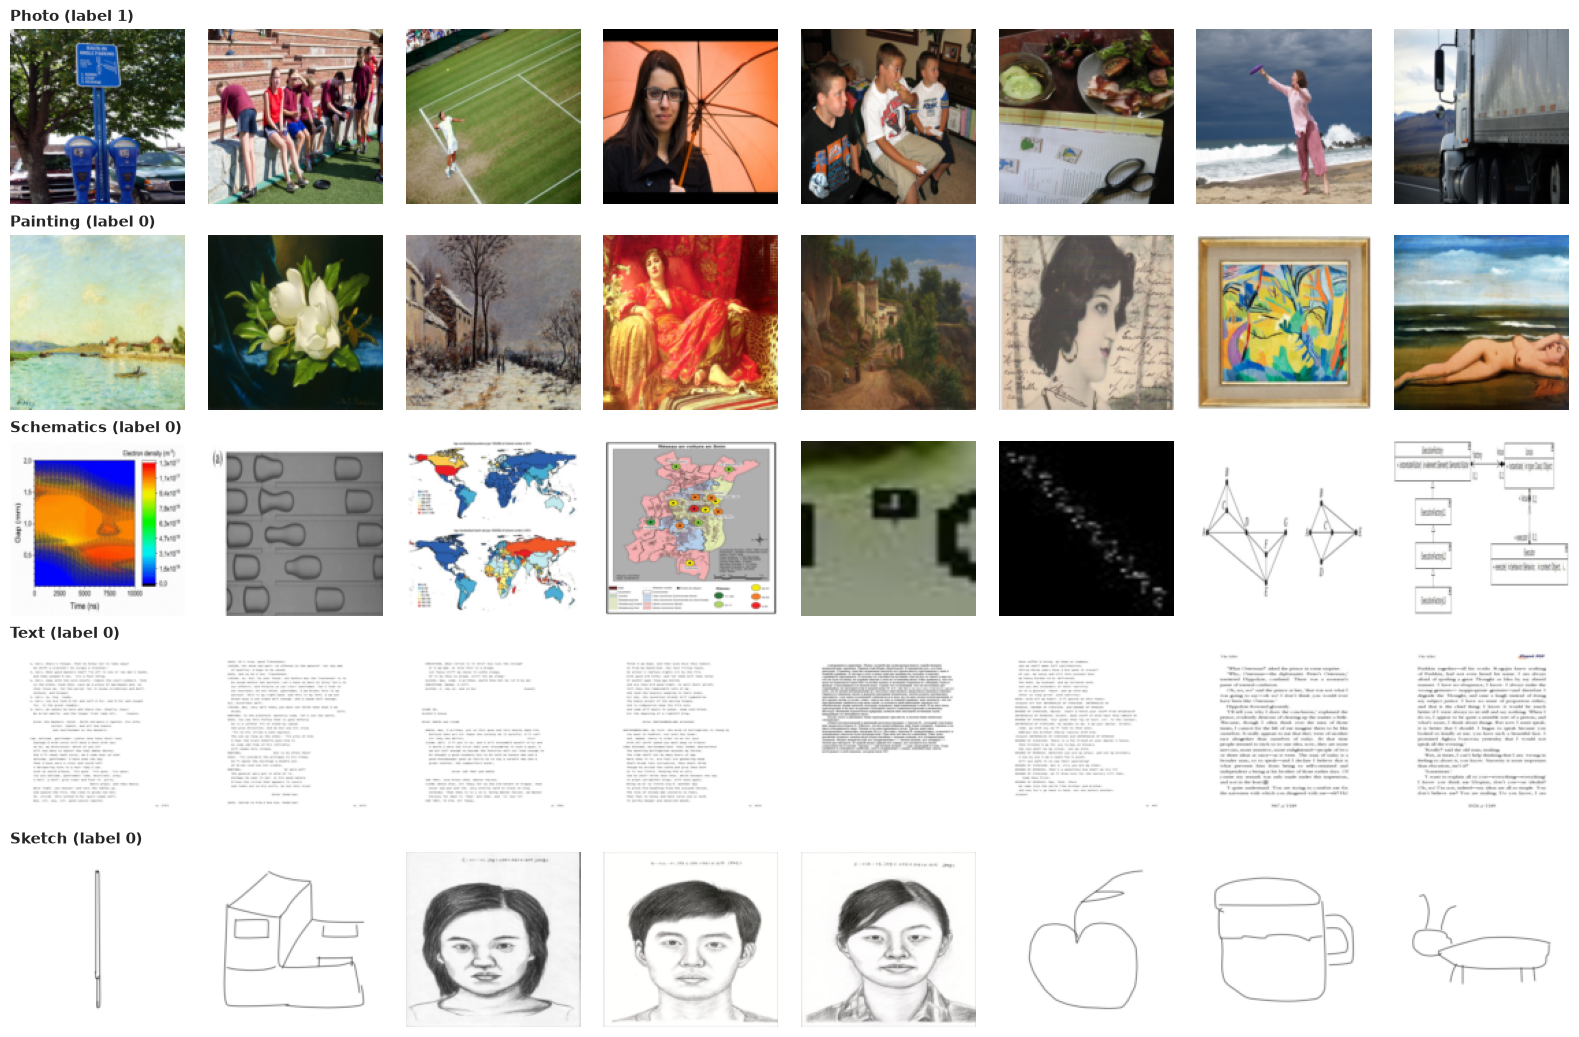

In [4]:
rng = np.random.default_rng(config.SEED)
fig, axes = plt.subplots(len(config.CLASSES), 8, figsize=(16, 2.1 * len(config.CLASSES)))
for r, source in enumerate(config.CLASSES):
    idx = rng.choice(meta.index[(meta["source"] == source) & (meta["subset"] == "pool")], 8, replace=False)
    for c, i in enumerate(idx):
        axes[r, c].imshow(X[i])
        axes[r, c].axis("off")
    axes[r, 0].set_title(source + (" (label 1)" if source == config.POSITIVE_CLASS else " (label 0)"),
                         loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Two simple statistics that already separate some classes
Mean **brightness**, and **colourfulness** (mean difference between the R, G and B channels, which is 0 for a
grayscale image). They give a feel for how hard each separation will be.

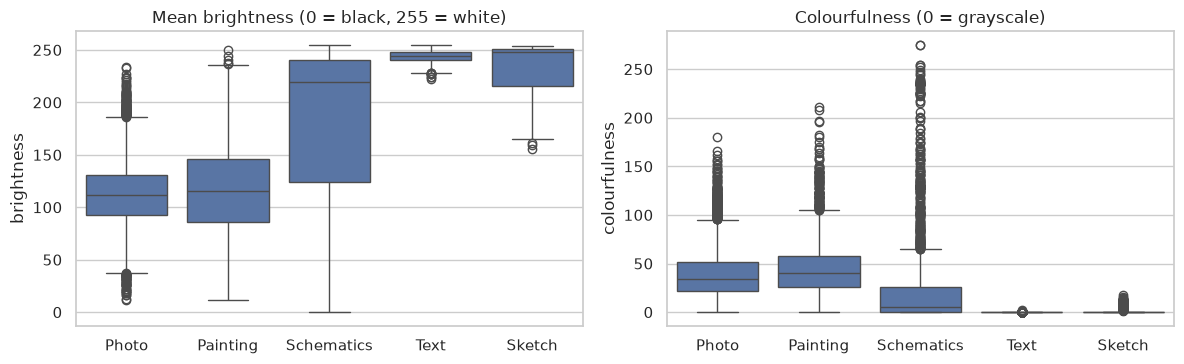

In [5]:
pix = X.astype(np.float32)
meta["brightness"] = pix.mean(axis=(1, 2, 3))
meta["colourfulness"] = (np.abs(pix[..., 0] - pix[..., 1]) + np.abs(pix[..., 1] - pix[..., 2])).mean(axis=(1, 2))
del pix

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=meta, x="source", y="brightness", order=config.CLASSES, ax=axes[0])
axes[0].set_title("Mean brightness (0 = black, 255 = white)")
sns.boxplot(data=meta, x="source", y="colourfulness", order=config.CLASSES, ax=axes[1])
axes[1].set_title("Colourfulness (0 = grayscale)")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [6]:
medians = meta.groupby("source")[["brightness", "colourfulness"]].median().loc[config.CLASSES]
display(Markdown(
    "**Results.** Median brightness: "
    + ", ".join(f"{s} {medians.loc[s, 'brightness']:.0f}" for s in config.CLASSES)
    + ". Median colourfulness: "
    + ", ".join(f"{s} {medians.loc[s, 'colourfulness']:.1f}" for s in config.CLASSES) + "."
))

**Results.** Median brightness: Photo 111, Painting 116, Schematics 220, Text 245, Sketch 248. Median colourfulness: Photo 34.2, Painting 40.4, Schematics 5.2, Text 0.0, Sketch 0.0.

Scanned text and sketches are very bright and nearly colourless, and diagrams are usually bright but vary a lot
(some are dark or colourful). A very simple classifier using thresholds on these two numbers would already
separate a good share of them.
Paintings are another story: their brightness and colour ranges overlap with those of photos. They can only be
told apart by texture and structure, which is exactly what a convolutional network can pick up. This is why
section 4 moves from the easiest classes to the hardest.

## 3. Train / validation / test split

The pool is split with stratification on the **source class** (not only on the binary label), so every image
type has the same share in all three sets:

| Set | Share | Role |
|---|---|---|
| `train` | 70% | learn the network weights |
| `val` (validation) | 15% | follow training epoch by epoch, tune and pick the model. This is the "test error" plotted in section 6 |
| `test` | 15% | final measurement only: never used to train, to pick a model or to set a threshold (sections 4 and 9) |
| `ext` | n/a | extended imbalanced test set, outside the pool, used the same way as `test` |

Picking the model by looking at the test set would leak information into the choice and make the reported
accuracy too optimistic. Hence the separate validation and test sets.

In [7]:
split_table = pd.crosstab(meta["source"], meta["split"]).loc[config.CLASSES, ["train", "val", "test", "ext"]]
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)

# leakage check: no file may appear in two sets
members = {s: set(meta.loc[meta["split"] == s, "member"]) for s in ["train", "val", "test", "ext"]}
for a in members:
    for b in members:
        if a < b:
            assert not (members[a] & members[b]), f"data leak between {a} and {b}"
print("OK: train / val / test / ext are pairwise disjoint.")

split,train,val,test,ext
source,,,,
Photo,4200,900,900,1000
Painting,1960,420,420,999
Schematics,840,180,180,1000
Text,840,180,180,1000
Sketch,560,120,120,606
TOTAL,8400,1800,1800,4605


OK: train / val / test / ext are pairwise disjoint.


Two helpers used throughout the notebook: fetch the data of one stage, and run a timed training.

In [8]:
def get_split(negative_sources=None):
    """{'train': (X, y, meta), 'val': ..., 'test': ...}. Photos are always included;
    `negative_sources` picks the negative classes (None = all of them)."""
    return {s: data.select(X, meta, s, negative_sources) for s in ("train", "val", "test")}


def run(split, epochs, early_stopping=False, patience=4, **model_kwargs):
    """Build a CNN (`model_kwargs` go to modeling.build_cnn), train it, return (model, history, seconds)."""
    keras.utils.set_random_seed(config.SEED)
    Xtr, ytr, _ = split["train"]
    Xva, yva, _ = split["val"]
    model = modeling.build_cnn(**model_kwargs)
    t0 = time.perf_counter()
    hist = modeling.train(
        model,
        data.make_dataset(Xtr, ytr, shuffle=True),
        data.make_dataset(Xva, yva),
        epochs=epochs,
        class_weight=data.class_weights(ytr),
        early_stopping=early_stopping,
        patience=patience,
        verbose=0,
    )
    return model, hist, time.perf_counter() - t0

## 4. Increasing difficulty

The brief suggests starting with the images that are easiest to tell apart from photos. We train **the same
network** (described in section 5) on four problems of increasing difficulty, adding one negative image type at
each stage:

| Stage | Photos against |
|---|---|
| 1 | scanned text |
| 2 | text + diagrams |
| 3 | text + diagrams + sketches |
| 4 | text + diagrams + sketches + **paintings** (the final problem) |

In stages 1 to 3 there are more photos than negatives, so we use **class weights** (`class_weight`) and report the
**balanced accuracy** (mean recall over the two classes) instead of the raw accuracy. Each stage is evaluated on its
own `test` set, which training never sees.

In [9]:
stage_rows, stage_per_source, stage_models = [], {}, {}
for stage, negatives in config.STAGES.items():
    split = get_split(negatives)
    model, hist, seconds = run(split, EPOCHS["stage"], early_stopping=True, patience=3)
    Xte, yte, mte = split["test"]
    proba = modeling.predict_proba(model, Xte)
    res = evaluation.evaluate_binary(yte, proba)
    per_src = evaluation.per_source_accuracy(mte, proba)
    worst = per_src.iloc[0]
    stage_rows.append({
        "stage": stage, "n_train": len(split["train"][1]), "epochs": len(hist), "time (s)": round(seconds),
        "balanced_acc": res["balanced_accuracy"], "precision": res["precision"], "recall": res["recall"],
        "F1": res["f1"], "ROC-AUC": res["roc_auc"], "hardest class": worst["source"],
        "accuracy on that class": worst["accuracy"],
    })
    stage_per_source[stage] = per_src.set_index("source")["accuracy"]
    stage_models[stage] = model
stage_df = pd.DataFrame(stage_rows).set_index("stage")
display(stage_df)

,n_train,epochs,time (s),balanced_acc,precision,recall,F1,ROC-AUC,hardest class,accuracy on that class
stage,,,,,,,,,,
1_photo_vs_text,5040,8,13,1.000,1.000,1.000,1.000,1.000,Photo,1.000
2_+schematics,5880,5,8,0.939,0.964,0.969,0.966,0.978,Schematics,0.817
3_+sketch,6440,8,10,0.966,0.974,0.982,0.978,0.994,Schematics,0.867
4_+painting,8400,8,10,0.869,0.867,0.873,0.870,0.947,Painting,0.755


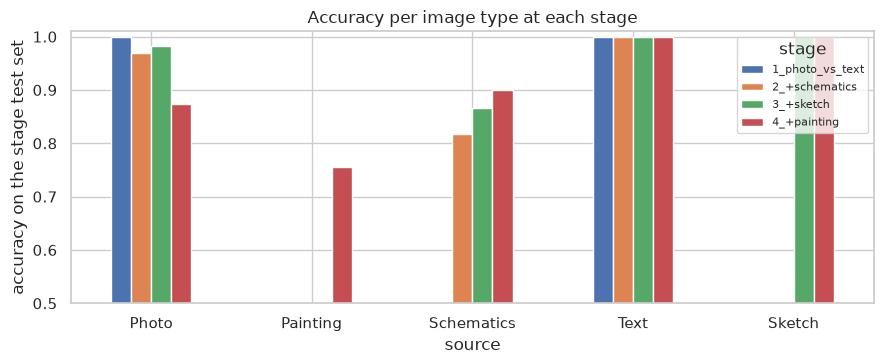

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
pd.DataFrame(stage_per_source).loc[config.CLASSES].plot.bar(ax=ax, rot=0)
ax.set_ylim(0.5, 1.01)
ax.set_ylabel("accuracy on the stage test set")
ax.set_title("Accuracy per image type at each stage")
ax.legend(title="stage", fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
last = stage_df.iloc[-1]
first = stage_df.iloc[0]
display(Markdown(
    f"**Results.** Stage 1 (photo vs text): balanced accuracy **{first['balanced_acc']:.3f}**. "
    f"Stage 4 (all classes, paintings included): **{last['balanced_acc']:.3f}**, F1 **{last['F1']:.3f}**. "
    f"At stage 4 the hardest class is **{last['hardest class']}** "
    f"(accuracy {last['accuracy on that class']:.3f}). "
    + ("This matches what we expected: realistic paintings look like photos and account for most errors."
       if last["hardest class"] == "Painting"
       else "Unexpectedly, paintings are not the main source of errors. This needs a closer look.")
))

**Results.** Stage 1 (photo vs text): balanced accuracy **1.000**. Stage 4 (all classes, paintings included): **0.869**, F1 **0.870**. At stage 4 the hardest class is **Painting** (accuracy 0.755). This matches what we expected: realistic paintings look like photos and account for most errors.

## 5. Network architecture

We use a **convolutional neural network (CNN)** designed for this problem. The code printed below is the code
actually used everywhere in this notebook (`src/tounum_cls/modeling.py`).

In [12]:
print(inspect.getsource(modeling._compile))   # loss, optimiser, metrics
print(inspect.getsource(modeling.build_cnn))  # architecture

def _compile(model: keras.Model, learning_rate: float = 1e-3) -> keras.Model:
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model

def build_cnn(
    filters: tuple[int, ...] = (16, 32, 64, 128),
    dense_units: int = 64,
    dropout: float = 0.0,
    l2: float = 0.0,
    augmentation: bool = False,
    img_size: int = config.IMG_SIZE,
    learning_rate: float = 1e-3,
    bn_momentum: float = 0.9,
    name: str = "cnn_photo",
) -> keras.Model:
    """Custom CNN for photo (1) vs non-photo (0).

    Input: uint8 images (img_size, img_size, 3); the /255 scaling is INSIDE the model.
    One block = Conv2D 3x3 (same padding) -> BatchNormalization -> ReLU -> MaxPooling2D 2x2.
    Head: GlobalAveragePooling2D -> Dense(dense_units, relu) -> [Dropout] -> Dense(1, sigmoid).
    `augmentation=True` adds random transformations that are only a

In [13]:
baseline = modeling.build_cnn()
baseline.summary()

Model: "cnn_photo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 128, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,481 (415.94 KB)

 Trainable params: 106,001 (414.07 KB)

 Non-trainable params: 480 (1.88 KB)

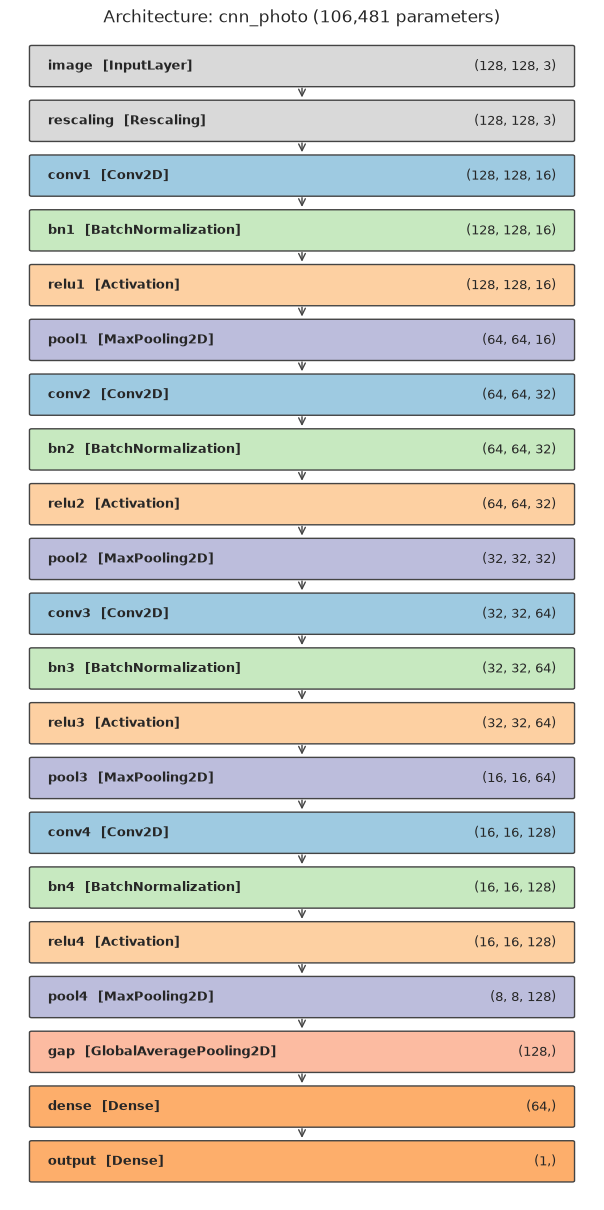

In [14]:
fig = evaluation.draw_architecture(baseline)
plt.show()

### 5.1 What each layer does

| Layer | Role |
|---|---|
| `Rescaling(1/255)` | maps pixels from [0, 255] to [0, 1]. It sits inside the model, so production code can feed raw images |
| `Conv2D 3×3` ×4 (16, 32, 64, 128 filters) | detects local patterns: edges and textures in the first blocks, more complex shapes in the last ones. The filters are learned, unlike the hand-made convolution filters of deliverable 2 |
| `BatchNormalization` | normalises the activations of each batch, which makes training faster and more stable |
| `ReLU` | the non-linearity `max(0, x)` |
| `MaxPooling2D 2×2` | halves the resolution: less computation and some tolerance to small shifts |
| `GlobalAveragePooling2D` | averages each feature map into a single number. This avoids a huge dense layer, so the model has few parameters and overfits less |
| `Dense(64, ReLU)` | combines the 128 features |
| `Dense(1, sigmoid)` | output: the probability *P(photo)* in [0, 1] |

### 5.2 Network parameters

In [15]:
rows = []
for layer in baseline.layers:
    rows.append({
        "layer": layer.name, "type": type(layer).__name__,
        "output shape": str(tuple(layer.output.shape)[1:]), "parameters": layer.count_params(),
    })
param_table = pd.DataFrame(rows)
display(param_table[param_table["parameters"] > 0])
trainable = int(sum(np.prod(w.shape) for w in baseline.trainable_weights))
non_trainable = int(sum(np.prod(w.shape) for w in baseline.non_trainable_weights))
print(f"Total: {baseline.count_params():,} parameters, of which {trainable:,} trainable and "
      f"{non_trainable:,} non-trainable (BatchNorm moving means and variances)")

,layer,type,output shape,parameters
2,conv1,Conv2D,"(128, 128, 16)",432
3,bn1,BatchNormalization,"(128, 128, 16)",64
6,conv2,Conv2D,"(64, 64, 32)",4608
7,bn2,BatchNormalization,"(64, 64, 32)",128
10,conv3,Conv2D,"(32, 32, 64)",18432
11,bn3,BatchNormalization,"(32, 32, 64)",256
14,conv4,Conv2D,"(16, 16, 128)",73728
15,bn4,BatchNormalization,"(16, 16, 128)",512
19,dense,Dense,"(64,)",8256
20,output,Dense,"(1,)",65


Total: 106,481 parameters, of which 106,001 trainable and 480 non-trainable (BatchNorm moving means and variances)


### 5.3 Loss function

The output is binary, so we use the **binary cross-entropy**. For an image with true label $y \in \{0, 1\}$ and a
predicted probability $\hat{p}$ = P(photo):

$$\mathcal{L}(y, \hat{p}) = -\big[\, y \log \hat{p} + (1 - y)\log(1 - \hat{p}) \,\big]$$

The loss is averaged over the batch. It is small when the network is both right and confident, and very large
when it is confidently wrong (a painting called "photo" with 99% confidence). It is the natural loss for a
sigmoid output (maximum likelihood of a Bernoulli variable) and gives better gradients than the squared error.

### 5.4 Optimisation algorithm

**Adam** (learning rate $10^{-3}$, $\beta_1 = 0.9$, $\beta_2 = 0.999$). Adam is stochastic gradient descent on
mini-batches (64 images here) that adapts the step of each parameter using a moving average of the gradient
(momentum) and of its square (scale). It is a reliable default that converges quickly without fine-tuning the
learning rate. We track the **accuracy** (share of images correctly classified at the 0.5 threshold) and the
**AUC** (how well photos are ranked above non-photos, whatever the threshold).

### 5.5 Why this architecture?
- **A CNN rather than a dense network**: sharing filters across the image uses its 2D structure with very few
  parameters (about 106k, against millions for a dense network on 128×128×3 pixels).
- **A small network**: the task is a single global decision, and a small network trains fast enough to be
  retrained many times for the comparisons of sections 4, 7 and 8.
- **Backed by results**: section 7 compares this network with a much smaller and a larger version, and section 10
  with a pre-trained network of several million parameters.

## 6. Training and learning curves

We train the reference model (*baseline*, no regularisation) on the **final** problem (stage 4: photos against
every other class). The curves compare training and validation (the "test error" of the brief) at each epoch,
for the loss and for the accuracy.

In [16]:
FINAL_SPLIT = get_split(None)
Xtr, ytr, mtr = FINAL_SPLIT["train"]
Xva, yva, mva = FINAL_SPLIT["val"]
Xte, yte, mte = FINAL_SPLIT["test"]
print(f"train {Xtr.shape[0]} | val {Xva.shape[0]} | test {Xte.shape[0]} | photos in train: {ytr.mean():.1%}")

baseline_model, baseline_hist, baseline_sec = run(FINAL_SPLIT, EPOCHS["main"])
print(f"Training done in {baseline_sec:.0f} s ({baseline_sec / len(baseline_hist):.1f} s per epoch)")
shown = sorted({i for i in (0, 1, 2, len(baseline_hist) // 2, len(baseline_hist) - 1) if i < len(baseline_hist)})
display(baseline_hist.round(4).set_index("epoch").iloc[shown])

train 8400 | val 1800 | test 1800 | photos in train: 50.0%


Training done in 15 s (0.7 s per epoch)


,accuracy,auc,loss,val_accuracy,val_auc,val_loss
epoch,,,,,,
1,0.800,0.874,0.428,0.746,0.901,0.483
2,0.836,0.916,0.358,0.843,0.935,0.356
3,0.854,0.929,0.332,0.863,0.946,0.302
11,0.905,0.968,0.227,0.876,0.966,0.289
20,0.930,0.982,0.172,0.915,0.976,0.203


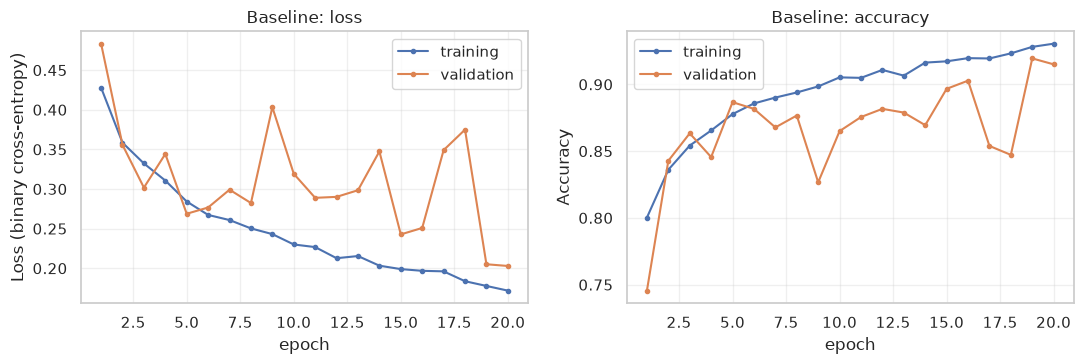

In [17]:
evaluation.plot_history(baseline_hist, "Baseline")
plt.show()

In [18]:
diag = evaluation.diagnose_fit(baseline_hist)
display(Markdown(
    f"**Results (baseline).** Final accuracy: training **{diag['train_acc']:.3f}**, "
    f"validation **{diag['val_acc']:.3f}** (gap {diag['gap_acc']:+.3f}). "
    f"Final loss: training {diag['train_loss']:.3f}, validation {diag['val_loss']:.3f}. "
    f"Lowest validation loss at epoch **{diag['best_epoch']}** out of {len(baseline_hist)} "
    f"(increase since that minimum: {diag['val_loss_drift']:+.3f}). Diagnosis: **{diag['verdict']}**."
))

**Results (baseline).** Final accuracy: training **0.930**, validation **0.915** (gap +0.015). Final loss: training 0.172, validation 0.203. Lowest validation loss at epoch **20** out of 20 (increase since that minimum: +0.000). Diagnosis: **balanced (no clear bias or variance problem)**.

**Reading the curves.**
- In the first epochs the validation curve can jump around, sometimes badly, because `BatchNormalization` uses
  moving statistics that need a few steps to settle. This is not a flaw of the model.
- If the training loss keeps falling while the validation loss goes back up, the network is **memorising** the
  training set (overfitting).
- If both curves stay high, the network is **too simple** or not trained long enough (underfitting).

## 7. Bias / variance analysis

- **High bias = underfitting**: the model is too rigid to capture the structure of the data. The error is high on
  both the training and the validation set.
- **High variance = overfitting**: the model fits the noise of the training data. The training error is low but
  the validation error is clearly higher (large gap).
- What we want: both errors low and close to each other.

A more complex model lowers the bias but raises the variance. We check this in two ways.

The automatic diagnoses use fixed thresholds (training accuracy below 0.90 means bias; a train-validation gap
above 0.05, or a validation loss more than 0.05 above its minimum, means variance). A case close to a threshold
can flip from one run to the next.

### 7.1 Three model capacities
Same data, same procedure; only the size of the network changes.

In [19]:
CAPACITY = {
    "too simple": dict(filters=(4, 8), dense_units=4),
    "baseline": dict(),
    "too complex": dict(filters=(32, 64, 128, 256), dense_units=256),
}
cap_hist, cap_models, cap_rows = {"baseline": baseline_hist}, {"baseline": baseline_model}, []
for name, kwargs in CAPACITY.items():
    if name == "baseline":
        model, hist, sec = baseline_model, baseline_hist, baseline_sec
    else:
        model, hist, sec = run(FINAL_SPLIT, EPOCHS["main"], **kwargs)
        cap_hist[name], cap_models[name] = hist, model
    d = evaluation.diagnose_fit(hist)
    cap_rows.append({"model": name, "parameters": model.count_params(), "train acc": d["train_acc"],
                     "val acc": d["val_acc"], "gap": d["gap_acc"], "min val loss": hist["val_loss"].min(),
                     "epoch of min": d["best_epoch"], "diagnosis": d["verdict"]})
cap_df = pd.DataFrame(cap_rows).set_index("model")
display(cap_df)

,parameters,train acc,val acc,gap,min val loss,epoch of min,diagnosis
model,,,,,,,
too simple,485,0.795,0.765,0.030,0.430,18,high bias (underfitting)
baseline,106481,0.930,0.915,0.015,0.203,20,balanced (no clear bias or variance problem)
too complex,455905,0.931,0.906,0.026,0.219,15,balanced (no clear bias or variance problem)


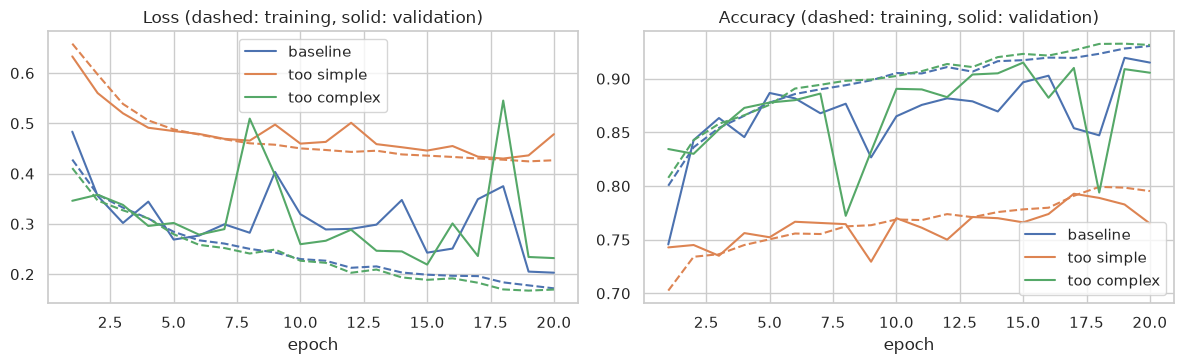

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, hist in cap_hist.items():
    line, = axes[0].plot(hist["epoch"], hist["loss"], ls="--")
    axes[0].plot(hist["epoch"], hist["val_loss"], color=line.get_color(), label=name)
    line, = axes[1].plot(hist["epoch"], hist["accuracy"], ls="--")
    axes[1].plot(hist["epoch"], hist["val_accuracy"], color=line.get_color(), label=name)
axes[0].set_title("Loss (dashed: training, solid: validation)")
axes[1].set_title("Accuracy (dashed: training, solid: validation)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

### 7.2 Learning curve: what happens with more data?
We train the baseline on a growing share of the training set (stratified by class) and compare the training and
validation accuracy at the end of training. The validation accuracy of a single epoch can move by several points
from one epoch to the next (section 6), so each point is the mean of the last three epochs. A **large gap that
closes as data grows** points to variance, which more images would reduce. Two curves that are **close but low**
point to bias, which more data will not fix.

,n_train,train acc,val acc
fraction,,,
0.10,840,0.878,0.816
0.25,2100,0.910,0.832
0.50,4200,0.920,0.830
1.00,8400,0.928,0.899


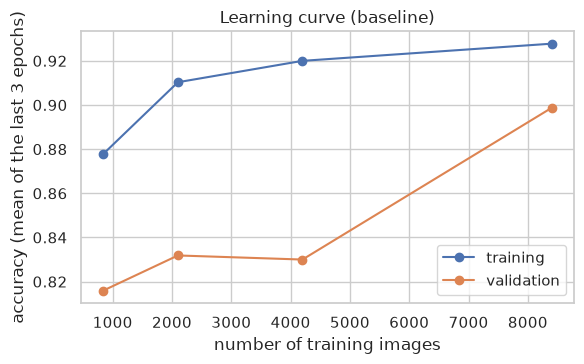

In [21]:
from sklearn.model_selection import train_test_split

curve_rows = []
for frac in (0.1, 0.25, 0.5, 1.0):
    if frac < 1.0:
        keep, _ = train_test_split(np.arange(len(ytr)), train_size=frac, stratify=mtr["source"], random_state=config.SEED)
    else:
        keep = np.arange(len(ytr))
    sub = {"train": (Xtr[keep], ytr[keep], mtr.iloc[keep]), "val": FINAL_SPLIT["val"], "test": FINAL_SPLIT["test"]}
    _, hist, _ = run(sub, EPOCHS["curve"])
    end = hist.tail(3)                                   # mean of the last three epochs
    curve_rows.append({"fraction": frac, "n_train": len(keep), "train acc": end["accuracy"].mean(),
                       "val acc": end["val_accuracy"].mean()})
curve_df = pd.DataFrame(curve_rows).set_index("fraction")
display(curve_df)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(curve_df["n_train"], curve_df["train acc"], marker="o", label="training")
ax.plot(curve_df["n_train"], curve_df["val acc"], marker="o", label="validation")
ax.set_xlabel("number of training images")
ax.set_ylabel("accuracy (mean of the last 3 epochs)")
ax.set_title("Learning curve (baseline)")
ax.legend()
plt.tight_layout()
plt.show()

In [22]:
small, big = curve_df.iloc[0], curve_df.iloc[-1]
delta_big = cap_df.loc["too complex", "val acc"] - cap_df.loc["baseline", "val acc"]
ratio_big = cap_df.loc["too complex", "parameters"] / cap_df.loc["baseline", "parameters"]
delta_small = cap_df.loc["too simple", "val acc"] - cap_df.loc["baseline", "val acc"]
capacity_note = (
    f" Multiplying the number of parameters by {ratio_big:.1f} changes the validation accuracy by {delta_big:+.3f}"
    + (", so the baseline already has enough capacity for this task." if abs(delta_big) < 0.01
       else (", so the larger model does better." if delta_big > 0 else ", so the larger model does worse."))
    + f" The \"too simple\" model is {delta_small:+.3f} away from the baseline."
)
display(Markdown(
    "**Results.** "
    f"Capacity: the \"too simple\" model ({cap_df.loc['too simple', 'parameters']:,} parameters) reaches "
    f"{cap_df.loc['too simple', 'val acc']:.3f} on validation, the baseline ({cap_df.loc['baseline', 'parameters']:,}) "
    f"{cap_df.loc['baseline', 'val acc']:.3f} and the \"too complex\" model "
    f"({cap_df.loc['too complex', 'parameters']:,}) {cap_df.loc['too complex', 'val acc']:.3f}. "
    f"Diagnoses: too simple, *{cap_df.loc['too simple', 'diagnosis']}*; baseline, "
    f"*{cap_df.loc['baseline', 'diagnosis']}*; too complex, *{cap_df.loc['too complex', 'diagnosis']}*. "
    f"Learning curve: with {int(small['n_train'])} images the train-validation gap is "
    f"{small['train acc'] - small['val acc']:+.3f}; with {int(big['n_train'])} images it is "
    f"{big['train acc'] - big['val acc']:+.3f}."
    + capacity_note
))

**Results.** Capacity: the "too simple" model (485 parameters) reaches 0.765 on validation, the baseline (106,481) 0.915 and the "too complex" model (455,905) 0.906. Diagnoses: too simple, *high bias (underfitting)*; baseline, *balanced (no clear bias or variance problem)*; too complex, *balanced (no clear bias or variance problem)*. Learning curve: with 840 images the train-validation gap is +0.062; with 8400 images it is +0.029. Multiplying the number of parameters by 4.3 changes the validation accuracy by -0.009, so the baseline already has enough capacity for this task. The "too simple" model is -0.150 away from the baseline.

**Interpretation.** A gap that shrinks as the number of images grows means we are in a **variance** regime: more
data, or regularisation, will help. A model whose training accuracy is itself too low is in a **bias** regime: it
needs more capacity or more epochs, not more data. The numbers above show which regime each configuration is in.

## 8. Improving the bias / variance trade-off

### 8.1 Available methods

| Method | Idea | Expected effect | Used here |
|---|---|---|---|
| **More data** | more examples, less memorisation | lower variance | limited to the sample (see 7.2) |
| **Data augmentation** | random transformations (flip, rotation, zoom, contrast) at every epoch, so the network never sees exactly the same image twice | lower variance | yes |
| **Dropout** | randomly switches off a share of the neurons at each step, which prevents co-adaptation | lower variance | yes (0.4) |
| **L2 regularisation** (*weight decay*) | adds $\lambda \sum w^2$ to the loss: large weights are penalised and the model gets smoother | lower variance | yes ($\lambda = 10^{-4}$) |
| **Early stopping** | stops training when the validation loss stops improving and restores the best weights | lower variance | yes (patience 5) |
| **Lower capacity** | fewer layers or filters | lower variance, higher bias | see 7.1 |
| **BatchNormalization** | normalises activations; slight regularising effect | stability | already in the network |
| **More capacity or epochs** | more filters, longer training | lower bias | see 7.1 |
| **Adaptive learning rate** | lower the step when validation stalls (`ReduceLROnPlateau`) | finer convergence | not used |
| **Transfer learning** | start from a network pre-trained on ImageNet | lower bias and variance with little data | section 10 |

### 8.2 Experiments
Same problem (stage 4), same seed. Each technique is tried **alone**, then **all together** (with early stopping).
Early stopping gets a larger epoch budget since it decides on its own when to stop.

In [23]:
IMPROVEMENTS = {
    "baseline": dict(kwargs=dict(), epochs=EPOCHS["main"], es=False),
    "+ augmentation": dict(kwargs=dict(augmentation=True), epochs=EPOCHS["main"], es=False),
    "+ dropout 0.4": dict(kwargs=dict(dropout=0.4), epochs=EPOCHS["main"], es=False),
    "+ L2 1e-4": dict(kwargs=dict(l2=1e-4), epochs=EPOCHS["main"], es=False),
    "+ early stopping": dict(kwargs=dict(), epochs=EPOCHS["improve"], es=True),
    "all combined": dict(kwargs=dict(augmentation=True, dropout=0.4, l2=1e-4), epochs=EPOCHS["improve"], es=True),
}
imp_hist, imp_models, imp_rows = {}, {}, []
for name, cfg in IMPROVEMENTS.items():
    if name == "baseline":
        model, hist, sec = baseline_model, baseline_hist, baseline_sec
    else:
        model, hist, sec = run(FINAL_SPLIT, cfg["epochs"], early_stopping=cfg["es"], patience=5, **cfg["kwargs"])
    imp_hist[name], imp_models[name] = hist, model
    d = evaluation.diagnose_fit(hist, restored_best=cfg["es"])  # early stopping: restored weights = best epoch
    val_metrics = model.evaluate(data.make_dataset(Xva, yva), verbose=0, return_dict=True)  # FINAL model weights
    imp_rows.append({"configuration": name, "epochs run": len(hist), "kept epoch": d["kept_epoch"],
                     "train acc (kept epoch)": d["train_acc"],
                     "train-val gap (kept epoch)": d["gap_acc"], "val loss (final model)": val_metrics["loss"],
                     "val acc (final model)": val_metrics["accuracy"], "diagnosis": d["verdict"],
                     "time (s)": round(sec)})
imp_df = pd.DataFrame(imp_rows).set_index("configuration")
display(imp_df)

,epochs run,kept epoch,train acc (kept epoch),train-val gap (kept epoch),val loss (final model),val acc (final model),diagnosis,time (s)
configuration,,,,,,,,
baseline,20,20,0.930,0.015,0.203,0.915,balanced (no clear bias or variance problem),15
+ augmentation,20,20,0.903,0.020,0.261,0.884,balanced (no clear bias or variance problem),26
+ dropout 0.4,20,20,0.914,0.005,0.215,0.908,balanced (no clear bias or variance problem),15
+ L2 1e-4,20,20,0.925,0.012,0.241,0.913,balanced (no clear bias or variance problem),15
+ early stopping,13,8,0.892,-0.006,0.255,0.898,high bias (underfitting),11
all combined,18,13,0.873,-0.017,0.287,0.891,high bias (underfitting),22


In [24]:
base = imp_df.loc["baseline"]
others = imp_df.drop(index="baseline")
lower_loss = others.index[others["val loss (final model)"] < base["val loss (final model)"]].tolist()
higher_acc = others.index[others["val acc (final model)"] > base["val acc (final model)"]].tolist()
display(Markdown("**Results.** Compared with the baseline (validation loss "
    f"{base['val loss (final model)']:.3f}, accuracy {base['val acc (final model)']:.3f}), "
    f"lower validation loss: {', '.join(lower_loss) or 'none'}; "
    f"higher validation accuracy: {', '.join(higher_acc) or 'none'}. "
    + (f"The early-stopping configurations get {EPOCHS['improve']} epochs instead of {EPOCHS['main']}, "
       "so the budgets are not identical." if EPOCHS["improve"] != EPOCHS["main"] else "")))

**Results.** Compared with the baseline (validation loss 0.203, accuracy 0.915), lower validation loss: none; higher validation accuracy: none. The early-stopping configurations get 25 epochs instead of 20, so the budgets are not identical.

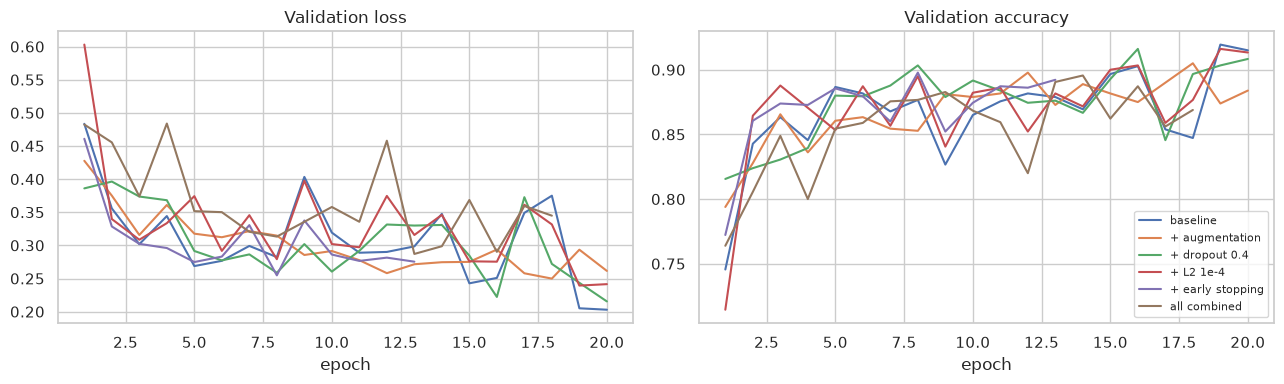

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, hist in imp_hist.items():
    axes[0].plot(hist["epoch"], hist["val_loss"], label=name)
    axes[1].plot(hist["epoch"], hist["val_accuracy"], label=name)
axes[0].set_title("Validation loss")
axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].set_ylim(top=min(1.5, axes[0].get_ylim()[1]))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [26]:
best_name = imp_df["val loss (final model)"].idxmin()
display(Markdown(
    f"**Model selection (validation set only).** The configuration with the lowest validation loss is "
    f"**{best_name}** (loss {imp_df.loc[best_name, 'val loss (final model)']:.4f}, "
    f"accuracy {imp_df.loc[best_name, 'val acc (final model)']:.3f})"
    + ("; none of the techniques lowered the validation loss in this run"
       + (", which is consistent with a baseline that shows no clear variance problem"
          if imp_df.loc["baseline", "diagnosis"].startswith("balanced") else "") + ". "
       if best_name == "baseline" else
       f"; the baseline gets {imp_df.loc['baseline', 'val loss (final model)']:.4f} / "
       f"{imp_df.loc['baseline', 'val acc (final model)']:.3f}. ")
    + "This is the custom CNN evaluated on the test sets in the next section."
))
final_model = imp_models[best_name]
final_hist = imp_hist[best_name]

**Model selection (validation set only).** The configuration with the lowest validation loss is **baseline** (loss 0.2029, accuracy 0.915); none of the techniques lowered the validation loss in this run, which is consistent with a baseline that shows no clear variance problem. This is the custom CNN evaluated on the test sets in the next section.

Curves of the selected model (training vs validation, loss and accuracy):

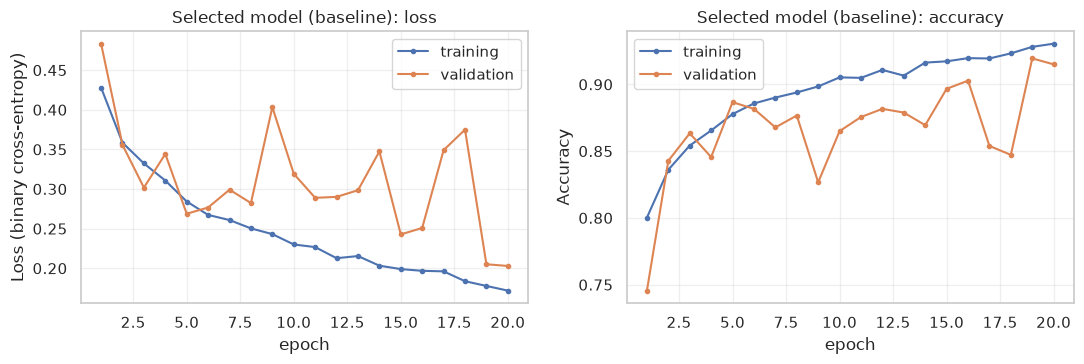

Diagnosis of the selected model (kept epoch: 20): training accuracy 0.930, validation 0.915, so **balanced (no clear bias or variance problem)**.

In [27]:
evaluation.plot_history(final_hist, f"Selected model ({best_name})")
plt.show()
d = evaluation.diagnose_fit(final_hist, restored_best=IMPROVEMENTS[best_name]["es"])
kept_kwargs = IMPROVEMENTS[best_name]["kwargs"]
reg_note = (" Note that with dropout and augmentation the training accuracy is measured with these perturbations "
            "switched on, so it is lower than it would be at inference time."
            if ("augmentation" in kept_kwargs or "dropout" in kept_kwargs) else "")
display(Markdown(
    f"Diagnosis of the selected model (kept epoch: {d['kept_epoch']}): training accuracy {d['train_acc']:.3f}, "
    f"validation {d['val_acc']:.3f}, so **{d['verdict']}**." + reg_note
))

## 9. Final evaluation

We now use the **`test`** set (balanced, never seen) and the **extended test set `ext`** (imbalanced, closer to a
real archive) with the model selected in section 8. Both are used for measurement only, never to train, to pick a
model or to set a threshold.

In [28]:
Xe, ye, me = data.select(X, meta, "ext")
results, probas = {}, {}
for label, (Xs, ys, ms) in {"test (balanced)": (Xte, yte, mte), "ext (realistic)": (Xe, ye, me)}.items():
    probas[label] = modeling.predict_proba(final_model, Xs)
    results[label] = evaluation.evaluate_binary(ys, probas[label])
res_df = pd.DataFrame(results).T
display(res_df[["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "tp", "fp", "fn", "tn"]])
print(f"Share of photos: test {yte.mean():.1%} | ext {ye.mean():.1%}")

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,tp,fp,fn,tn
test (balanced),0.904,0.904,0.914,0.892,0.903,0.970,803.0,76.0,97.0,824.0
ext (realistic),0.932,0.922,0.804,0.905,0.852,0.979,905.0,220.0,95.0,3385.0


Share of photos: test 50.0% | ext 21.7%


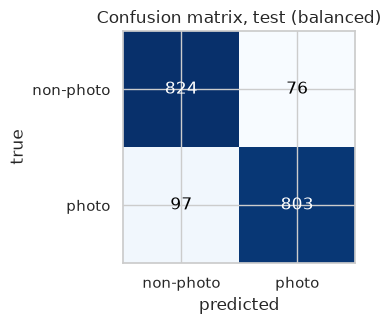

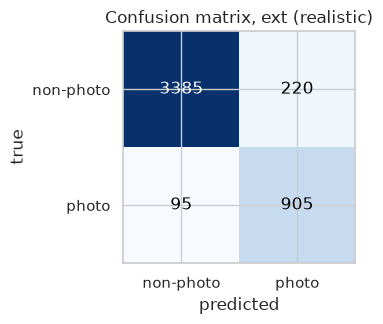

In [29]:
for label, (Xs, ys, ms) in {"test (balanced)": (Xte, yte, mte), "ext (realistic)": (Xe, ye, me)}.items():
    evaluation.plot_confusion(ys, probas[label], title=f"Confusion matrix, {label}")
    plt.show()

### 9.1 Where does the model go wrong?
Accuracy per image type on the extended test set (the larger one):

,source,n,accuracy
0,Painting,999,0.877
1,Schematics,1000,0.903
2,Photo,1000,0.905
3,Sketch,606,1.000
4,Text,1000,1.000


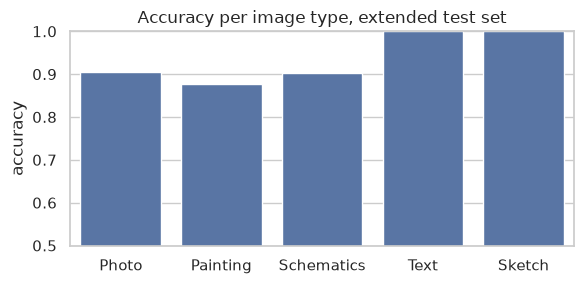

In [30]:
per_src_ext = evaluation.per_source_accuracy(me, probas["ext (realistic)"])
display(per_src_ext)
fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(data=per_src_ext, x="source", y="accuracy", order=config.CLASSES, ax=ax)
ax.set_ylim(0.5, 1.0)
ax.set_xlabel("")
ax.set_title("Accuracy per image type, extended test set")
plt.tight_layout()
plt.show()

**False positives**: non-photos taken for photos, most confident first. These are the costly errors for TouNum
because they end up in the captioning module.

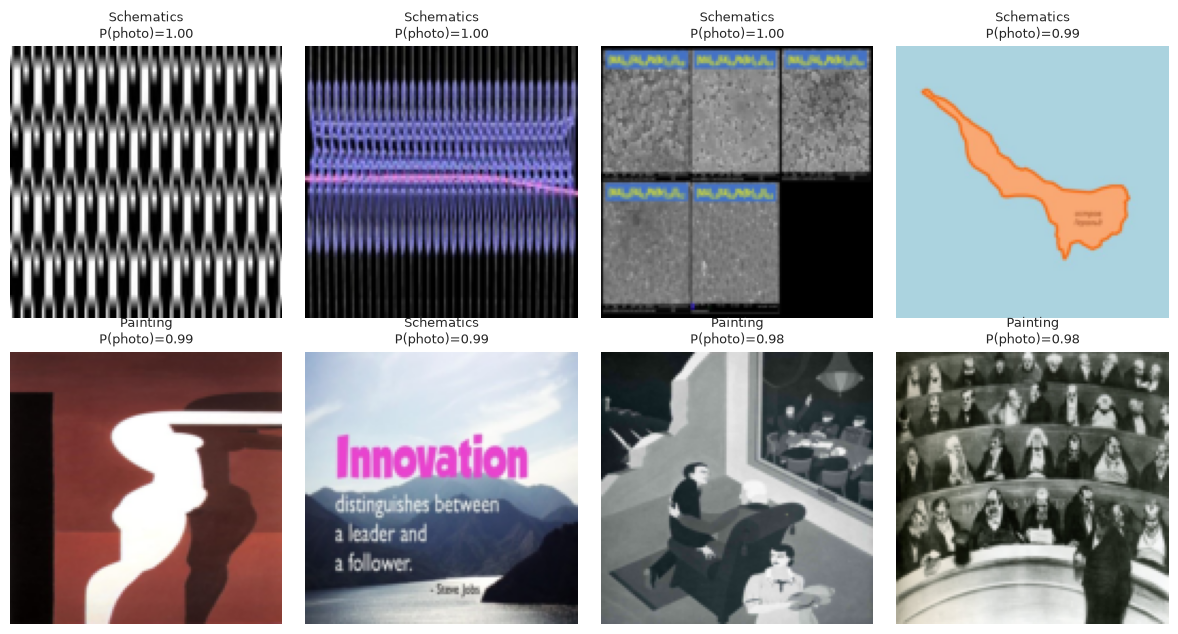

In [31]:
fig = evaluation.show_errors(Xe, me, probas["ext (realistic)"], kind="fp", n=8)
if fig is None:
    print("No false positive on the extended test set.")
else:
    plt.show()

**False negatives**: photos that were rejected, most confident first.

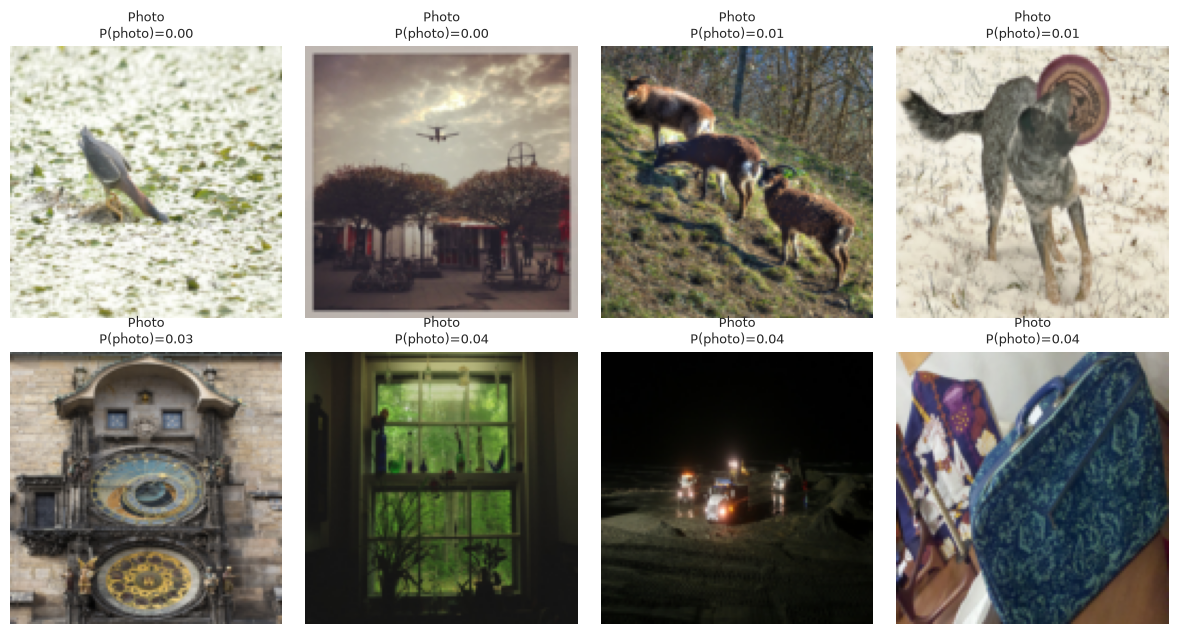

In [32]:
fig = evaluation.show_errors(Xe, me, probas["ext (realistic)"], kind="fn", n=8)
if fig is None:
    print("No false negative on the extended test set.")
else:
    plt.show()

### 9.2 Choosing the decision threshold
0.5 is only a default. For TouNum, **letting a non-photo through** (false positive, lower precision) and
**losing a photo** (false negative, lower recall) do not cost the same, so the threshold is a business decision.
The table below is descriptive: it shows how precision and recall move with the threshold on the extended test
set, where photos are a minority. A production threshold should be set on validation data (or fresh data) and then
confirmed, not tuned on this table, which is a measurement set.

,precision,recall,F1,false positives,false negatives
threshold,,,,,
0.1,0.606,0.983,0.750,638,17
0.3,0.737,0.952,0.831,340,48
0.5,0.804,0.905,0.852,220,95
0.7,0.864,0.834,0.849,131,166
0.9,0.934,0.676,0.784,48,324


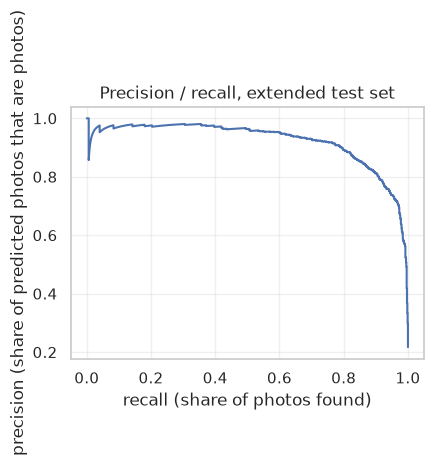

In [33]:
rows = []
for thr in (0.1, 0.3, 0.5, 0.7, 0.9):
    r = evaluation.evaluate_binary(ye, probas["ext (realistic)"], threshold=thr)
    rows.append({"threshold": thr, "precision": r["precision"], "recall": r["recall"], "F1": r["f1"],
                 "false positives": r["fp"], "false negatives": r["fn"]})
display(pd.DataFrame(rows).set_index("threshold"))
evaluation.plot_precision_recall(ye, probas["ext (realistic)"], "Precision / recall, extended test set")
plt.show()

In [34]:
res_t, res_e = results["test (balanced)"], results["ext (realistic)"]
worst = per_src_ext.iloc[0]
display(Markdown(
    f"**Results.** Balanced test set: accuracy **{res_t['accuracy']:.3f}**, F1 **{res_t['f1']:.3f}**, "
    f"ROC-AUC **{res_t['roc_auc']:.3f}**. Extended test set (about {ye.mean():.0%} photos): accuracy "
    f"**{res_e['accuracy']:.3f}**, precision **{res_e['precision']:.3f}**, recall **{res_e['recall']:.3f}**, "
    f"F1 **{res_e['f1']:.3f}**. The worst classified image type is **{worst['source']}** "
    f"(accuracy {worst['accuracy']:.3f}). "
    + ("Precision is lower on the extended set because photos are a minority there: for the same false positive "
       "rate, false positives weigh more against fewer true positives. This is the metric to watch in production."
       if res_e["precision"] < res_t["precision"] - 0.01
       else "Precision holds up despite the class imbalance of the extended set.")
))

**Results.** Balanced test set: accuracy **0.904**, F1 **0.903**, ROC-AUC **0.970**. Extended test set (about 22% photos): accuracy **0.932**, precision **0.804**, recall **0.905**, F1 **0.852**. The worst classified image type is **Painting** (accuracy 0.877). Precision is lower on the extended set because photos are a minority there: for the same false positive rate, false positives weigh more against fewer true positives. This is the metric to watch in production.

### 9.3 Saving the custom CNN
The model contains its own pre-processing (`Rescaling`), so it only needs 128×128×3 `uint8` images.
`data.load_image` does the conversion (RGB and resizing) from any jpg or png file.

In [35]:
SAVE_DIR = Path(tempfile.gettempdir()) / "tounum_quick" if QUICK else config.MODELS_DIR   # QUICK never touches models/
SAVE_DIR.mkdir(parents=True, exist_ok=True)


def save_and_check(model, filename):
    """Save a model, reload it and check that both give the same predictions."""
    path = SAVE_DIR / filename
    model.save(path)
    reloaded = keras.models.load_model(path)
    assert np.allclose(reloaded.predict(Xte[:32], verbose=0), model.predict(Xte[:32], verbose=0), atol=1e-5)
    shown = path.relative_to(config.PROJECT_ROOT) if path.is_relative_to(config.PROJECT_ROOT) else path
    print(f"Saved {shown} ({path.stat().st_size / 1e6:.1f} MB), reload checked.")
    return reloaded


save_and_check(final_model, "photo_cnn.keras")


def predict_photo(model, paths, threshold=0.5):
    """Classify image files. Returns a DataFrame (file, P(photo), is_photo)."""
    batch = np.stack([data.load_image(p) for p in paths])
    proba = modeling.predict_proba(model, batch)
    return pd.DataFrame({"file": [Path(p).name for p in paths], "P(photo)": proba.round(3),
                         "is_photo": proba >= threshold})

Saved models/photo_cnn.keras (1.4 MB), reload checked.


## 10. Comparison with a pre-trained network (MobileNetV2)

To put the custom architecture in perspective, we compare it with **MobileNetV2** pre-trained on ImageNet (over a
million images), used as a **frozen** feature extractor: only the head (one sigmoid `Dense` layer) is trained.
This is *transfer learning*. The ImageNet weights are downloaded on first use.

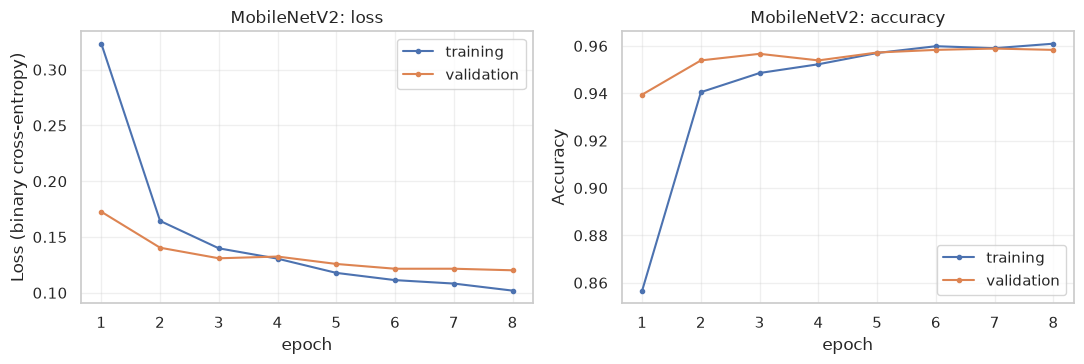

,parameters,trainable,val accuracy,val F1,val AUC,test accuracy,test F1,test AUC,ext accuracy,ext F1,ext AUC,ext acc. Painting,training time (s)
model,,,,,,,,,,,,,
custom CNN (baseline),106481,106001,0.915,0.914,0.976,0.904,0.903,0.970,0.932,0.852,0.979,0.877,15
frozen MobileNetV2 + head,2259265,1281,0.958,0.958,0.991,0.946,0.946,0.988,0.971,0.936,0.994,0.938,14


In [36]:
def summarize(model, name):
    row = {"model": name, "parameters": model.count_params(),
           "trainable": int(sum(np.prod(w.shape) for w in model.trainable_weights))}
    for label, (Xs, ys, ms) in {"val": (Xva, yva, mva), "test": (Xte, yte, mte), "ext": (Xe, ye, me)}.items():
        p = modeling.predict_proba(model, Xs)
        r = evaluation.evaluate_binary(ys, p)
        row[f"{label} accuracy"], row[f"{label} F1"], row[f"{label} AUC"] = r["accuracy"], r["f1"], r["roc_auc"]
        if label == "ext":
            acc = evaluation.per_source_accuracy(ms, p).set_index("source")["accuracy"]
            row["ext acc. Painting"] = acc.get("Painting", np.nan)
    return row


compare_rows = [summarize(final_model, f"custom CNN ({best_name})")]
mnet = None
try:
    mnet = modeling.build_mobilenet()
    keras.utils.set_random_seed(config.SEED)
    t0 = time.perf_counter()
    mnet_hist = modeling.train(mnet, data.make_dataset(Xtr, ytr, shuffle=True), data.make_dataset(Xva, yva),
                               epochs=EPOCHS["mobilenet"], class_weight=data.class_weights(ytr), verbose=0)
    mnet_sec = time.perf_counter() - t0
    row = summarize(mnet, "frozen MobileNetV2 + head")
    row["training time (s)"] = round(mnet_sec)
    compare_rows.append(row)
    evaluation.plot_history(mnet_hist, "MobileNetV2")
    plt.show()
except Exception as exc:  # e.g. no network access to download the ImageNet weights
    mnet = None
    print(f"MobileNetV2 comparison skipped: {type(exc).__name__}: {exc}")
compare_rows[0]["training time (s)"] = round(imp_df.loc[best_name, "time (s)"])
compare_df = pd.DataFrame(compare_rows).set_index("model")
display(compare_df)

In [37]:
production_model, production_name = final_model, "custom CNN"
if len(compare_df) == 2:
    a, b = compare_df.iloc[0], compare_df.iloc[1]
    gain = b["val accuracy"] - a["val accuracy"]  # the decision uses VALIDATION; test and ext are only reported
    ratio = b["parameters"] / a["parameters"]
    if gain > 0.02:
        production_model, production_name = mnet, "MobileNetV2"
        verdict = (f"MobileNetV2 has a better validation accuracy (+{gain:.3f}) with {ratio:.0f} times more "
                   "parameters, only about a thousand of which are trained. It becomes the production model. "
                   "The custom CNN stays available as a lighter model that does not depend on pre-trained weights.")
    elif gain < -0.02:
        verdict = (f"The custom CNN has a better validation accuracy (+{-gain:.3f}) with {ratio:.0f} times fewer "
                   "parameters. It stays the production model.")
    else:
        verdict = "Validation accuracy is about the same (gap under 0.02): the lighter custom CNN stays the production model."
    display(Markdown(
        f"**Results.** Custom CNN: {int(a['parameters']):,} parameters, accuracy {a['val accuracy']:.3f} (validation) / "
        f"{a['test accuracy']:.3f} (test) / {a['ext accuracy']:.3f} (ext), paintings {a['ext acc. Painting']:.3f}. "
        f"MobileNetV2: {int(b['parameters']):,} parameters ({int(b['trainable']):,} trainable), accuracy "
        f"{b['val accuracy']:.3f} / {b['test accuracy']:.3f} / {b['ext accuracy']:.3f}, paintings "
        f"{b['ext acc. Painting']:.3f}. {verdict} The decision is based on the validation set; the test and ext "
        "figures are reported for information."
    ))
else:
    verdict = "The MobileNetV2 comparison could not run, so the custom CNN is the production model."
    print(verdict)

**Results.** Custom CNN: 106,481 parameters, accuracy 0.915 (validation) / 0.904 (test) / 0.932 (ext), paintings 0.877. MobileNetV2: 2,259,265 parameters (1,281 trainable), accuracy 0.958 / 0.946 / 0.971, paintings 0.938. MobileNetV2 has a better validation accuracy (+0.043) with 21 times more parameters, only about a thousand of which are trained. It becomes the production model. The custom CNN stays available as a lighter model that does not depend on pre-trained weights. The decision is based on the validation set; the test and ext figures are reported for information.

### 10.1 Saving the production model
The production model is saved as `models/photo_classifier.keras`. This is the file the full pipeline of
deliverable 3 loads. Like the custom CNN, it takes raw 128×128×3 `uint8` images.

In [38]:
classifier = save_and_check(production_model, "photo_classifier.keras")
demo = me.sample(8, random_state=config.SEED)
out = predict_photo(classifier, demo["path"].tolist())
out["true type"] = demo["source"].to_numpy()
display(out)

Saved models/photo_classifier.keras (9.6 MB), reload checked.


,file,P(photo),is_photo,true type
0,m1-002-01-sz1.jpg,0.006,False,Sketch
1,photo_8226.jpg,1.000,True,Photo
2,293_1_1_sz1.jpg,0.018,False,Sketch
3,photo_1232.jpg,0.999,True,Photo
4,text_08045.jpg,0.001,False,Text
5,painting_01181.jpg,0.003,False,Painting
6,painting_06920.jpg,0.007,False,Painting
7,painting_03269.jpg,0.129,False,Painting


## 11. Conclusion, limits and next steps

### Key figures
The figures below are recomputed on every run from the results of the previous sections.

In [39]:
worst_src = per_src_ext.iloc[0]
display(Markdown(
    f"**Summary.** Selected custom CNN configuration (chosen on validation): **{best_name}**, "
    f"kept epoch {d['kept_epoch']}. Accuracy: validation **{imp_df.loc[best_name, 'val acc (final model)']:.3f}**, "
    f"test **{res_t['accuracy']:.3f}**, extended test **{res_e['accuracy']:.3f}**. "
    f"On the extended test set: precision **{res_e['precision']:.3f}**, recall **{res_e['recall']:.3f}**. "
    f"Worst classified image type (extended test): **{worst_src['source']}** (accuracy {worst_src['accuracy']:.3f}). "
    f"Production model: **{production_name}**. {verdict}"
))

**Summary.** Selected custom CNN configuration (chosen on validation): **baseline**, kept epoch 20. Accuracy: validation **0.915**, test **0.904**, extended test **0.932**. On the extended test set: precision **0.804**, recall **0.905**. Worst classified image type (extended test): **Painting** (accuracy 0.877). Production model: **MobileNetV2**. MobileNetV2 has a better validation accuracy (+0.043) with 21 times more parameters, only about a thousand of which are trained. It becomes the production model. The custom CNN stays available as a lighter model that does not depend on pre-trained weights.

### What was built
1. A **reproducible workflow from raw archives to a trained model**: archive inventory, disjoint sampling,
   selective extraction, normalisation (RGB, 128×128), cache, stratified split.
2. A **custom CNN of about 106k parameters** trained with Adam on the binary cross-entropy, checked on problems of
   increasing difficulty (section 4) and compared with a pre-trained network (section 10).
3. A **bias/variance analysis** backed by numbers (sections 6 to 8) and a comparison of regularisation techniques.
4. An **evaluation on test sets that were never used for training or model selection**, one balanced and one
   realistic (section 9), with an error analysis and a discussion of the threshold.
5. **Saved models**: `models/photo_cnn.keras` (custom CNN) and `models/photo_classifier.keras` (production model,
   used by the pipeline of deliverable 3), plus an inference function (`predict_photo`).

### Limits
- **Sample size**: 12,000 modelling images out of about 41,400. Training on everything could do slightly better.
  The counts are set in `config.py`.
- **128×128 resolution and stretching**: fine details are lost (they help tell a realistic painting from a photo)
  and elongated pages are distorted.
- **What counts as a "photo"**: the label comes from the source archive. A hyper-realistic painting or a heavily
  edited photo stays ambiguous, even for a person, and labelling mistakes in the archives cap the reachable
  accuracy.
- **Generalisation**: the model is evaluated on images from the same sources. Images from other sources (other
  scanners, other document types, other periods) may lower the results.
- **Image quality**: all training images are reasonably clean. Deliverable 2 (denoising) checks how the filter
  behaves on noisy images.
- **Reproducibility**: small numerical differences are possible from one machine to another, and between a CPU
  and a GPU run.

### Next steps
- Train on all the archives at a higher resolution;
- improve on realistic paintings (targeted augmentation, fine-tuning the last MobileNetV2 blocks);
- set the threshold with TouNum based on the cost of each type of error (section 9.2);
- plug this filter in front of the pre-processing and captioning modules (deliverables 2 and 3) and measure its
  effect end to end;
- monitor production (share of images predicted as photos, a sample checked by hand) to catch data drift.